# VaR y ES de una cartera: convención de signos, simulación histórica y un primer conteo de excepciones

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el cuaderno 01 del tema 01 (instalar y abrir un artefacto)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar las dos convenciones de signos del riesgo de mercado, decir cuál guarda el motor y cuál usan los documentos versionados, y convertir entre ellas con la función del propio motor;
- calcular un valor en riesgo (VaR) y una pérdida esperada (ES) a partir de una muestra de retornos, y decir en cuántas observaciones se apoya de verdad la estimación de la cola;
- producir un pronóstico de simulación histórica a un paso que no usa información del día pronosticado ni posterior;
- contar las excepciones de un pronóstico de VaR, compararlas con las esperadas y leer la prueba de proporción de fallas de Kupiec;
- reconstruir las banderas de excepción de un pronóstico versionado, incluso en una ventana cuyos retornos realizados no se versionan.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Los valores de luz del motor, con las palabras que imprime este cuaderno
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C11 (pronóstico y backtesting de VaR y ES) tal como Contraste lo versiona. Se leen dos archivos.

- `data/derived/C11/fx-2008.json`: una posición larga en el euro frente al dólar de EE. UU., de julio de 2008 a junio de 2009, 251 días de pronóstico. Los retornos diarios son el cambio simple del tipo de cambio H.10 de la Reserva Federal (clase de licencia `mirror-allowed`), así que el archivo **versiona las pérdidas realizadas**. Es el archivo donde cada número de este cuaderno se puede recalcular desde los retornos.
- `data/derived/C11/calm-2004-06.json`: una cartera mixta (50 por ciento renta variable de EE. UU., 30 por ciento bono del Tesoro a 10 años, 20 por ciento euro) en los años tranquilos 2004 a 2006, 750 días de pronóstico. Uno de sus componentes es el retorno accionario de Kenneth French, una fuente **solo derivada**: el archivo guarda los pronósticos de los 17 modelos y sus días de excepción, y retiene las pérdidas realizadas.

Los dos archivos llevan los pronósticos de cada modelo de la escalera que Contraste ejecutó (los estimadores son el tema del cuaderno 02). Aquí usamos uno: `hs-250`, simulación histórica sobre los últimos 250 días. La celda siguiente carga los dos archivos e imprime lo que contienen.

In [2]:
# Cargar las dos ventanas versionadas (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
fx = json.loads((ROOT / "data" / "derived" / "C11" / "fx-2008.json").read_text(encoding="utf-8"))
calm = json.loads((ROOT / "data" / "derived" / "C11" / "calm-2004-06.json").read_text(encoding="utf-8"))

for label, doc in (("fx-2008", fx), ("calm-2004-06", calm)):
    out = doc["outputs"]
    print(label, "|", out["window"]["title"]["es"])
    print("  cartera:", out["portfolio"]["description"]["es"])
    print("  días de pronóstico:", out["window"]["n_forecast_days"], "| primero:", out["grid"]["dates"][0], "| último:", out["grid"]["dates"][-1])
    print("  pérdidas realizadas:", out["grid"]["realised_loss"]["status"])
    print("  niveles de cola:", [lv["alpha"] for lv in out["levels"]], "| modelos:", len(out["models"]))
    print("  calculado por riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

fx-2008 | Divisas 2008: el euro frente al dolar en la crisis
  cartera: Posicion larga en el euro frente al dolar: el retorno simple diario de dolares por euro (H.10).
  días de pronóstico: 251 | primero: 2008-07-01 | último: 2009-06-30
  pérdidas realizadas: included
  niveles de cola: [0.01, 0.025] | modelos: 17
  calculado por riskvalidation 0.7.0 | instalado 0.8.1
calm-2004-06 | Calma 2004 a 2006: la ventana de control
  cartera: Una cartera mixta de 50 por ciento renta variable de EE. UU., 30 por ciento bono par a 10 anos y 20 por ciento euro, reequilibrada a diario a pesos constantes.
  días de pronóstico: 750 | primero: 2004-01-02 | último: 2006-12-29
  pérdidas realizadas: withheld-derived-only
  niveles de cola: [0.01, 0.025] | modelos: 17
  calculado por riskvalidation 0.7.0 | instalado 0.8.1


## Método

### Paso 1: dos maneras de escribir el mismo número

La literatura de riesgo de mercado usa dos convenciones de signos, y mezclarlas es el error silencioso más común en un informe de VaR.

- **Convención de pérdidas** (Basilea, McNeil, Frey y Embrechts): la pérdida es $L = -X$ para un retorno $X$, el nivel de confianza $\alpha$ es cercano a 1 (0,99; 0,975) y el VaR y la ES son números positivos.
- **Convención de retornos** (Patton, Ziegel y Chen, 2019): el nivel de cola $\alpha$ es pequeño (0,01; 0,025), $v = F^{-1}(\alpha)$ es el VaR y $e = \frac{1}{\alpha}\int_0^{\alpha} F^{-1}(u)\,du$ es la ES, ambos negativos en la práctica, con $e \le v$.

El motor guarda los pronósticos en la **convención de retornos**, porque la pérdida de puntuación del cuaderno 05 la necesita, y cambia el signo en un solo lugar, la capa de reporte. Los documentos versionados guardan **pérdidas positivas**, como decimales del valor de la cartera: un VaR de 0,0144 significa 1,44 por ciento de la cartera. La celda siguiente lee la declaración del archivo y aplica las dos funciones de conversión del motor a un pronóstico versionado.

In [3]:
# Leer la convención declarada y convertir un pronóstico versionado entre las dos convenciones con las funciones del motor
from riskvalidation.market.conventions import from_loss_numbers, to_loss_numbers

sign = fx["outputs"]["sign_convention"]
print("el motor guarda:", sign["engine_convention"], "| el documento guarda:", sign["document_convention"])

hs250 = {m["model_id"]: m for m in fx["outputs"]["models"]}["hs-250"]
level_1pct = hs250["by_level"][0]
var_doc = np.array(level_1pct["var"][:3])          # números de pérdida positivos, como se versionan
var_engine = from_loss_numbers(var_doc)            # la convención de retornos: números negativos
print("VaR versionado (pérdidas):     ", var_doc)
print("como lo guarda el motor:       ", var_engine)
print("de vuelta a pérdidas:          ", to_loss_numbers(var_engine))
print("ida y vuelta exacta:", bool(np.array_equal(to_loss_numbers(var_engine), var_doc)))

el motor guarda: return-negative | el documento guarda: positive-loss
VaR versionado (pérdidas):      [0.01438435 0.01438435 0.01438435]
como lo guarda el motor:        [-0.01438435 -0.01438435 -0.01438435]
de vuelta a pérdidas:           [0.01438435 0.01438435 0.01438435]
ida y vuelta exacta: True


### Paso 2: VaR y ES desde una muestra

Con $N$ retornos ordenados $r_{(1)} \le \dots \le r_{(N)}$ y $k = \lceil \alpha N \rceil$, el VaR empírico es el $k$-ésimo retorno más pequeño y la ES empírica es la integral de cola de la función cuantil empírica, en la que el $k$-ésimo retorno lleva solo la fracción de peso que sobra (la función `var_es_from_sample` del motor, `market/conventions.py`):

$$\widehat{\mathrm{VaR}}_\alpha = r_{(k)}, \qquad \widehat{\mathrm{ES}}_\alpha = \frac{\sum_{i<k} r_{(i)} + (\alpha N - (k-1))\, r_{(k)}}{\alpha N}$$

La muestra son los 251 retornos realizados de la posición en euros, $y = -\text{pérdida}$. Llamamos al motor y luego verificamos su respuesta contra la definición, armando los pesos a mano: peso 1 en cada uno de los primeros $k-1$ retornos y el sobrante en el $k$-ésimo. Es una verificación de la fórmula sobre una muestra; no es una segunda implementación del estimador.

In [4]:
# VaR y ES de los 251 retornos realizados en ambos niveles de cola, y verificación de la definición con pesos explícitos
from riskvalidation.market.conventions import var_es_from_sample

loss = np.array(fx["outputs"]["grid"]["realised_loss"]["loss"])
y = -loss                                           # retornos: la convención del motor
n = y.size
print("retornos:", n, "| media:", round(float(y.mean()), 6), "| desviación estándar:", round(float(y.std()), 6))

ordered = np.sort(y)
for alpha in (0.01, 0.025):
    var, es = var_es_from_sample(y, alpha)
    k = int(np.ceil(alpha * n - 1e-9))
    weights = np.ones(k)
    weights[-1] = alpha * n - (k - 1)               # el k-ésimo retorno lleva solo lo que sobra
    es_by_hand = float((weights * ordered[:k]).sum() / (alpha * n))
    print(f"alfa {alpha}: k = {k}, alfa N = {alpha * n:.3f}, pesos {weights.round(3)}")
    print(f"  VaR {var:.6f} | ES {es:.6f} | en pérdidas {-var:.6f} y {-es:.6f}")
    print("  la ES a mano es igual a la del motor:", bool(np.isclose(es_by_hand, es)), "| ES no mayor que el VaR:", bool(es <= var))

retornos: 251 | media: -0.000407 | desviación estándar: 0.010608
alfa 0.01: k = 3, alfa N = 2.510, pesos [1.   1.   0.51]
  VaR -0.023915 | ES -0.027216 | en pérdidas 0.023915 y 0.027216
  la ES a mano es igual a la del motor: True | ES no mayor que el VaR: True
alfa 0.025: k = 7, alfa N = 6.275, pesos [1.    1.    1.    1.    1.    1.    0.275]
  VaR -0.020861 | ES -0.024265 | en pérdidas 0.020861 y 0.024265
  la ES a mano es igual a la del motor: True | ES no mayor que el VaR: True


Una cola de 1 por ciento sobre 251 días son $\alpha N = 2{,}51$ observaciones: el VaR es el tercer peor día y la ES promedia los dos peores días y 0,51 del tercero. La estimación es exacta como definición y frágil como medición. La celda siguiente quita el peor día y recalcula, para mostrar cuánto mueve una sola observación la cola en cada nivel.

In [5]:
# Quitar el peor día y recalcular VaR y ES: cuánto mueve una sola observación la estimación de la cola
trimmed = np.delete(y, int(np.argmin(y)))
print("peor día quitado:", round(float(y.min()), 6), "| retornos restantes:", trimmed.size)
for alpha in (0.01, 0.025):
    var_all, es_all = var_es_from_sample(y, alpha)
    var_cut, es_cut = var_es_from_sample(trimmed, alpha)
    print(f"alfa {alpha}: VaR {-var_all:.6f} a {-var_cut:.6f} (cambio {100 * (var_cut / var_all - 1):.1f}%) | "
          f"ES {-es_all:.6f} a {-es_cut:.6f} (cambio {100 * (es_cut / es_all - 1):.1f}%)")

peor día quitado: -0.029585 | retornos restantes: 250
alfa 0.01: VaR 0.023915 a 0.022501 (cambio -5.9%) | ES 0.027216 a 0.024678 (cambio -9.3%)
alfa 0.025: VaR 0.020861 a 0.020379 (cambio -2.3%) | ES 0.024265 a 0.022864 (cambio -5.8%)


### Paso 3: un pronóstico de simulación histórica a un paso

Un pronóstico es una afirmación hecha **antes** del día al que se refiere. La simulación histórica toma los retornos de los últimos $W$ días como los escenarios de mañana y lee el VaR y la ES de esa muestra. Para el pronóstico del día $t$, la función `historical_var_es(returns, alpha, window)` del motor debe recibir solo los retornos con fecha anterior a $t$, el más reciente al final; entregarle el propio día $t$ volvería inútil el backtest.

El escalón `hs-250` de Contraste usa 250 días, y su primera ventana de estimación termina antes de que el archivo empiece. El archivo tiene solo 251 días, así que aquí usamos una ventana más corta, $W = 100$, y pronosticamos los últimos 151 días con retornos dentro del archivo. La ventana es una elección de este cuaderno; el `hs-250` versionado se lee en el paso 5.

In [6]:
# Pronosticar cada día solo con los W retornos previos y marcar los días en que el retorno cayó bajo el VaR pronosticado
from riskvalidation.market.historical import historical_var_es

W = 100
forecasts = {}
for alpha in (0.01, 0.025):
    var_path, es_path = [], []
    for t in range(W, n):
        var_t, es_t = historical_var_es(y[:t], alpha, W)     # y[:t] termina el día anterior a t: sin mirar hacia adelante
        var_path.append(var_t)
        es_path.append(es_t)
    var_path, es_path = np.array(var_path), np.array(es_path)
    flags = y[W:] < var_path                                  # excepción: el retorno está bajo el VaR (la pérdida lo supera)
    forecasts[alpha] = (var_path, es_path, flags)
    print(f"alfa {alpha}: días pronosticados {flags.size} | excepciones {int(flags.sum())} | esperadas {alpha * flags.size:.2f}")

alfa 0.01: días pronosticados 151 | excepciones 1 | esperadas 1.51
alfa 0.025: días pronosticados 151 | excepciones 4 | esperadas 3.78


### Paso 4: la prueba de Kupiec sobre el conteo de excepciones

Si el VaR es correcto, cada día tiene probabilidad $\alpha$ de una excepción, de manera independiente, de modo que el conteo $x$ en $T$ días es binomial con parámetros $T$ y $\alpha$. Kupiec (1995) compara la proporción observada $\hat\pi = x/T$ con $\alpha$ mediante una razón de verosimilitud:

$$LR_{POF} = -2\ln\frac{(1-\alpha)^{T-x}\,\alpha^{x}}{(1-\hat\pi)^{T-x}\,\hat\pi^{x}} \;\xrightarrow{d}\; \chi^2_1$$

La función `kupiec_pof(exceedances, alpha)` del motor devuelve este estadístico, su valor p asintótico y, en `metric`, el valor p binomial **exacto**, que importa cuando el conteo esperado es pequeño (la ley asintótica es mala guía con un conteo esperado de 1,5). Su luz es una compuerta interna de Contraste sobre el valor p asintótico (ámbar bajo 0,10, roja bajo 0,05), no un umbral regulatorio. La celda siguiente la ejecuta sobre los dos pronósticos del paso 3.

In [7]:
# Prueba de proporción de fallas de Kupiec sobre las banderas del paso 3 (estadístico, p asintótico, p exacto, luz)
from riskvalidation.validation.market import kupiec_pof

for alpha in (0.01, 0.025):
    flags = forecasts[alpha][2]
    result = kupiec_pof(flags, alpha, model_id="hs-100")
    print(f"alfa {alpha}: excepciones {result.n_events} de {result.n} | esperadas {result.extras['expected_events']:.2f}")
    print(f"  LR_POF {result.statistic:.4f} | p asintótico {result.p_value:.4f} | p binomial exacto {result.metric:.4f} | luz {LIGHT[result.light.value]}")

alfa 0.01: excepciones 1 de 151 | esperadas 1.51
  LR_POF 0.1975 | p asintótico 0.6567 | p binomial exacto 1.0000 | luz verde
alfa 0.025: excepciones 4 de 151 | esperadas 3.78
  LR_POF 0.0135 | p asintótico 0.9075 | p binomial exacto 0.7927 | luz verde


### Paso 5: el pronóstico versionado y las banderas reconstruidas

El pronóstico `hs-250` versionado por Contraste para la misma ventana permite hacer el mismo conteo sobre la escalera real. El VaR y la ES versionados son pérdidas positivas; un día es una excepción cuando la pérdida realizada está **por encima** del VaR. Reconstruimos las banderas desde las pérdidas realizadas de este archivo, las comparamos con los `exceedance_days` que guarda el artefacto y volvemos a correr Kupiec sobre ellas. El artefacto se calculó con un motor más antiguo que el instalado aquí, así que la celda imprime la versión que lo calculó junto al recálculo (reserva R4 de la convención).

In [8]:
# Reconstruir las banderas de excepción del pronóstico hs-250 versionado desde las pérdidas realizadas y compararlas con los días guardados
committed_tests = {(t["model_id"], t["test_id"], t["segment"]): t for t in fx["tests"]}
print("calculado por riskvalidation", fx["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
for level in hs250["by_level"]:
    alpha = level["alpha"]
    var_loss = np.array(level["var"])
    flags = loss > var_loss                                    # la regla de excepción de la convención del documento
    stored = level["exceedance_days"]
    again = kupiec_pof(flags, alpha, model_id="hs-250")
    row = committed_tests[("hs-250", "market.kupiec_pof", f"alpha={alpha:g}")]
    print(f"alfa {alpha}: excepciones {int(flags.sum())} (guardadas {level['n_exceedances']}) | mismos días: {list(np.flatnonzero(flags)) == stored}")
    print(f"  esperadas {level['expected_exceedances']:.2f} | p de Kupiec ahora {again.p_value:.6f} | versionado {row['p_value']:.6f} | luz {LIGHT[again.light.value]} / {LIGHT[row['light']]}")
    print(f"  excepciones guardadas antes del día {W}: {sum(day < W for day in stored)} de {len(stored)}")

calculado por riskvalidation 0.7.0 | instalado 0.8.1
alfa 0.01: excepciones 10 (guardadas 10) | mismos días: True
  esperadas 2.51 | p de Kupiec ahora 0.000330 | versionado 0.000330 | luz rojo / rojo
  excepciones guardadas antes del día 100: 6 de 10
alfa 0.025: excepciones 13 (guardadas 13) | mismos días: True
  esperadas 6.28 | p de Kupiec ahora 0.017215 | versionado 0.017215 | luz rojo / rojo
  excepciones guardadas antes del día 100: 9 de 13


### Paso 6: una ventana cuyos retornos no se versionan

La ventana tranquila contiene un retorno de Kenneth French, así que sus pérdidas realizadas se retienen. El artefacto guarda igual, para cada modelo y nivel, los **días en que la pérdida superó al VaR** (`exceedance_days`, índices sobre las 750 fechas de pronóstico) y la trayectoria del VaR. Eso es todo lo que necesitan las pruebas de excepciones: una prueba del conteo lee banderas, no retornos. Reconstruimos las 750 banderas desde los días guardados, las contamos y volvemos a correr Kupiec.

In [9]:
# Reconstruir las 750 banderas de la ventana tranquila desde los días de excepción guardados y volver a correr Kupiec
calm_hs = {m["model_id"]: m for m in calm["outputs"]["models"]}["hs-250"]
calm_tests = {(t["model_id"], t["test_id"], t["segment"]): t for t in calm["tests"]}
dates = calm["outputs"]["grid"]["dates"]
for level in calm_hs["by_level"]:
    alpha = level["alpha"]
    flags = np.zeros(level["n_scored"], dtype=bool)
    flags[level["exceedance_days"]] = True
    again = kupiec_pof(flags, alpha, model_id="hs-250")
    row = calm_tests[("hs-250", "market.kupiec_pof", f"alpha={alpha:g}")]
    print(f"alfa {alpha}: {flags.size} días | excepciones {int(flags.sum())} | esperadas {level['expected_exceedances']:.2f}")
    print(f"  primera excepción {dates[level['exceedance_days'][0]]}, última {dates[level['exceedance_days'][-1]]}")
    print(f"  p de Kupiec ahora {again.p_value:.6f} | versionado {row['p_value']:.6f} | p exacto {again.metric:.4f} | luz {LIGHT[again.light.value]} / {LIGHT[row['light']]}")

alfa 0.01: 750 días | excepciones 9 | esperadas 7.50
  primera excepción 2004-03-10, última 2006-06-05
  p de Kupiec ahora 0.593559 | versionado 0.593559 | p exacto 0.5777 | luz verde / verde
alfa 0.025: 750 días | excepciones 22 | esperadas 18.75
  primera excepción 2004-01-28, última 2006-07-05
  p de Kupiec ahora 0.459214 | versionado 0.459214 | p exacto 0.4127 | luz verde / verde


La última celda dibuja las dos ventanas. A la izquierda, la posición en euros: la pérdida realizada de cada día (barras), el VaR y la ES de `hs-250` versionados al 1 por ciento (líneas) y los días de excepción (puntos rojos). A la derecha, la ventana tranquila: la trayectoria del VaR versionado al 1 por ciento y los días en que la pérdida lo superó. Los dos paneles tienen escalas distintas a propósito: son carteras distintas.

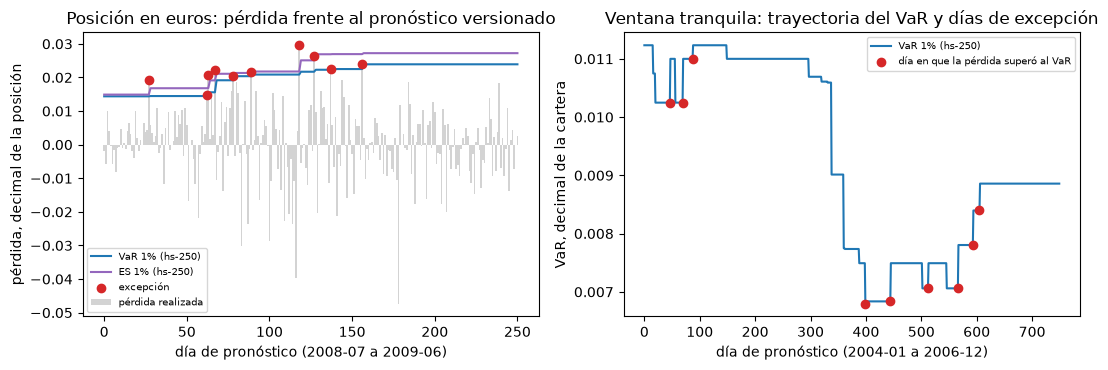

In [10]:
# Dibujar la posición en euros frente a su pronóstico hs-250 y la trayectoria del VaR de la ventana tranquila con sus días de excepción
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))

days = np.arange(loss.size)
var_fx, es_fx = np.array(level_1pct["var"]), np.array(level_1pct["es"])
hit = loss > var_fx
left.bar(days, loss, color="lightgrey", width=1.0, label="pérdida realizada")
left.plot(days, var_fx, color="tab:blue", label="VaR 1% (hs-250)")
left.plot(days, es_fx, color="tab:purple", label="ES 1% (hs-250)")
left.scatter(days[hit], loss[hit], color="tab:red", zorder=3, label="excepción")
left.set_xlabel("día de pronóstico (2008-07 a 2009-06)")
left.set_ylabel("pérdida, decimal de la posición")
left.set_title("Posición en euros: pérdida frente al pronóstico versionado")
left.legend(fontsize=7)

calm_level = calm_hs["by_level"][0]
var_calm = np.array(calm_level["var"])
right.plot(var_calm, color="tab:blue", label="VaR 1% (hs-250)")
right.scatter(calm_level["exceedance_days"], var_calm[calm_level["exceedance_days"]], color="tab:red", zorder=3, label="día en que la pérdida superó al VaR")
right.set_xlabel("día de pronóstico (2004-01 a 2006-12)")
right.set_ylabel("VaR, decimal de la cartera")
right.set_title("Ventana tranquila: trayectoria del VaR y días de excepción")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Resultados

- **Convención.** El VaR versionado es un número de pérdida positivo (0,014384 en los primeros días de la ventana en euros) y el motor lo guarda como retorno negativo (-0,014384); la ida y vuelta por `from_loss_numbers` y `to_loss_numbers` es exacta. Un informe que no dice qué convención usa es ambiguo por un signo.
- **La cola se apoya en pocos días.** Sobre los 251 retornos, el VaR al 1 por ciento es 2,39 por ciento de la posición y la ES 2,72 por ciento, y los pesos de la cola son 1, 1 y 0,51: tres días. Quitar el peor día mueve el VaR en -5,9 por ciento y la ES en -9,3 por ciento al 1 por ciento, y en -2,3 y -5,8 por ciento al 2,5 por ciento. Una ES estimada así es más sensible que el VaR, y una ventana corta la hace más sensible aún.
- **Un primer backtest.** La simulación histórica de 100 días pronosticó los últimos 151 días con 1 excepción al 1 por ciento (1,51 esperadas) y 4 al 2,5 por ciento (3,78 esperadas); Kupiec no rechaza (p asintótico 0,657 y 0,908). Con una excepción, el valor p binomial exacto (1,000) y el asintótico (0,657) están lejos: es el caso de conteo pequeño que el motor señala.
- **El `hs-250` versionado en el año de crisis.** Supera su VaR al 1 por ciento 10 veces contra 2,51 esperadas (p de Kupiec 0,00033, rojo) y su VaR al 2,5 por ciento 13 veces contra 6,28 (p 0,017, rojo). Seis de las diez excepciones al 1 por ciento caen antes del día 100 de la ventana, en los primeros meses de la crisis, que el pronóstico de 100 días del paso 3 no puntúa; los dos conteos son sobre días distintos y no se comparan uno a uno.
- **La ventana tranquila.** `hs-250` tiene 9 excepciones al 1 por ciento en 750 días (7,50 esperadas, p 0,594, verde) y 22 al 2,5 por ciento (18,75 esperadas, p 0,459). Las banderas reconstruidas solo desde los días de excepción guardados dan exactamente los valores p versionados, de modo que una ventana solo derivada se puede someter a backtest de conteo. Los artefactos se calcularon con el motor 0.7.0 y el cuaderno corre el 0.8.1; los valores p recalculados igualan a los versionados con seis decimales.

Lo que este cuaderno no muestra: la dependencia entre excepciones (cuaderno 03), el pronóstico de ES (cuaderno 04), los otros estimadores (cuaderno 02) ni cómo ordenarlos (cuaderno 05).

## Resumen

- El motor guarda VaR y ES en la convención de retornos (números negativos) y los documentos versionados guardan pérdidas positivas; `to_loss_numbers` y `from_loss_numbers` son el único lugar donde cambia el signo.
- Un VaR muestral es un estadístico de orden y la ES un promedio de cola con peso fraccionario en la última observación; al 1 por ciento sobre unos 250 días se apoyan en dos o tres días, así que una observación los mueve de forma visible.
- Un pronóstico se hace con información fechada antes del día al que se refiere. Contar cuántas veces la pérdida realizada lo superó, frente a las $\alpha T$ esperadas, es el primer backtest, y la prueba de Kupiec dice si el conteo es compatible con el nivel nominal; con un conteo esperado pequeño, lee el valor p exacto junto al asintótico.
- Las pruebas de excepciones necesitan banderas, no retornos: una ventana cuyos retornos se retienen por licencia se puede igual someter a backtest desde los días de excepción guardados.

**Qué probar después.** Cambia `W` en el paso 3 a 60 y a 150 y mira el conteo de excepciones y el valor p de Kupiec; luego continúa con el cuaderno 02, que recorre toda la escalera de estimadores.

## Referencias

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2); la convención de retornos, ecuaciones 1 y 2. https://arxiv.org/abs/1707.05108
- Comité de Supervisión Bancaria de Basilea (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Pritsker, M. (2001), The hidden dangers of historical simulation, Federal Reserve Board FEDS 2001-27. https://www.federalreserve.gov/Pubs/feds/2001/200127/200127pap.pdf
- Los tipos de cambio H.10 de la Reserva Federal y la biblioteca de datos de Kenneth French son las fuentes de las dos ventanas; solo se versionan valores derivados (véase la página del caso).